# Kinyarwanda Sentiment Classification: Word2Vec + BiLSTM/GRU

Sequence models on the same data and splits as the baseline notebook. Word2Vec embeddings are trained on the training tweets and fed to bidirectional LSTM and GRU classifiers.

## Setup

In [1]:
!pip install -q gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 73.2 MB/s eta 0:00:00


In [2]:
import re, json, random, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from datasets import load_dataset
from gensim.models import Word2Vec
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


## Data
Loading and cleaning are the same as in the baseline notebook.

In [3]:
base = "hf://datasets/shmuhammad/AfriSenti-twitter-sentiment@refs%2Fconvert%2Fparquet/kin"
ds = load_dataset("parquet", data_files={
    "train":      f"{base}/train/0000.parquet",
    "validation": f"{base}/validation/0000.parquet",
    "test":       f"{base}/test/0000.parquet",
})
label_names = ds["train"].features["label"].names
print("Labels:", label_names)

kin/train/0000.parquet: reconstructing file:   0%|          |  0.00B /  270kB            

kin/train/0000.parquet: downloading bytes:           |  0.00B            

kin/validation/0000.parquet: reconstructing file:   0%|          |  0.00B / 66.8kB            

kin/validation/0000.parquet: downloading bytes:           |  0.00B            

kin/test/0000.parquet: reconstructing file:   0%|          |  0.00B / 86.3kB            

kin/test/0000.parquet: downloading bytes:           |  0.00B            

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

Labels: ['positive', 'neutral', 'negative']


In [4]:
def to_df(split):
    df = ds[split].to_pandas()
    df["label_name"] = df["label"].map(lambda i: label_names[i])
    return df

def clean(text):
    text = re.sub(r"@user", " ", text).lower()
    return re.sub(r"\s+", " ", text).strip()

train_df, val_df, test_df = to_df("train"), to_df("validation"), to_df("test")
for d in (train_df, val_df, test_df):
    d["clean"] = d["tweet"].apply(clean)

y_train, y_val, y_test = (d["label"].tolist() for d in (train_df, val_df, test_df))
print(len(train_df), len(val_df), len(test_df))

3302 827 1026


## Tokenisation and Word2Vec
Tweets are split into words, punctuation marks, emojis and links (one token each). Word2Vec (skip-gram, 100 dimensions) is trained on the training tweets only, so nothing from validation or test reaches the embeddings. Words seen fewer than twice are mapped to `<unk>`. The corpus is small, which limits embedding quality.

In [5]:
def tokenize(text):
    return re.findall(r"https?://\S+|\w+|[^\w\s]", text)

train_tok = [tokenize(t) for t in train_df["clean"]]
val_tok   = [tokenize(t) for t in val_df["clean"]]
test_tok  = [tokenize(t) for t in test_df["clean"]]

print("Training tokens:", sum(len(t) for t in train_tok))
print("Example:", train_tok[0][:15])

Training tokens: 55381
Example: ['hhhhhh', 'ntabyihogoza', ',', 'ubu', 'x', 'abo', 'yishe', 'bangana', 'ik']


In [6]:
EMB_DIM = 100
w2v = Word2Vec(sentences=train_tok, vector_size=EMB_DIM, window=5, min_count=2,
               sg=1, epochs=30, seed=SEED, workers=1)
print("Word2Vec vocabulary:", len(w2v.wv))

for w in ["neza", "nabi", "mwiza"]:
    if w in w2v.wv:
        print(f"{w:>6} ->", [x for x, _ in w2v.wv.most_similar(w, topn=5)])

Word2Vec vocabulary: 4350
  neza -> ['https://t.co/8sadsncbh5', 'nzakingura', 'https://t.co/7tq0tmkywi', 'abagirire', 'abakingurire']
  nabi -> ['ngoyo', 'bonse', 'ariho', 'amatiku', 'mani']
 mwiza -> ['uzakubere', '🍷', '🥂', 'bihebuje', 'uburinzi']


In [7]:
PAD, UNK, MAX_LEN = 0, 1, 64
vocab = ["<pad>", "<unk>"] + list(w2v.wv.index_to_key)
word2idx = {w: i for i, w in enumerate(vocab)}

def encode(tokens):
    ids = [word2idx.get(t, UNK) for t in tokens][:MAX_LEN]
    return ids or [UNK]

train_ids = [encode(t) for t in train_tok]
val_ids   = [encode(t) for t in val_tok]
test_ids  = [encode(t) for t in test_tok]

val_unk = sum(i == UNK for ids in val_ids for i in ids) / sum(len(ids) for ids in val_ids)
print(f"Vocabulary: {len(vocab)}  |  validation tokens mapped to <unk>: {val_unk:.1%}")

emb_matrix = np.random.default_rng(SEED).normal(0, 0.1, (len(vocab), EMB_DIM)).astype("float32")
emb_matrix[PAD] = 0
for w, i in word2idx.items():
    if w in w2v.wv:
        emb_matrix[i] = w2v.wv[w]
emb_matrix = torch.tensor(emb_matrix)

Vocabulary: 4352  |  validation tokens mapped to <unk>: 28.1%


### Observations
- The training corpus is small: 55,381 tokens, of which 4,350 distinct words appear at least twice.
- 28.1% of validation tokens fall outside that vocabulary and map to `<unk>`, a large share for a word-level model. Kinyarwanda's long inflected words and the varied spellings in tweets are likely contributors.
- Nearest neighbours are only partly meaningful. "mwiza" sits close to celebratory emojis, but the neighbours of "neza" include links and rare verb forms, and those of "nabi" show no obvious sentiment link. With this little text the embeddings pick up co-occurrence quirks more than meaning.

## Model
Embedding layer, then a bidirectional LSTM or GRU (128 units per direction), dropout, and a linear layer with three outputs. The final forward and backward hidden states are concatenated as the tweet representation, and padding is handled with packed sequences. The loss is cross-entropy with class weights, matching the balanced weighting used in the baseline.

In [8]:
HIDDEN, DROPOUT = 128, 0.3
LR, BATCH_SIZE = 1e-3, 32
MAX_EPOCHS, PATIENCE = 30, 4

class RNNClassifier(nn.Module):
    def __init__(self, rnn_type, emb_mode):
        super().__init__()
        if emb_mode == "random":
            self.emb = nn.Embedding(len(vocab), EMB_DIM, padding_idx=PAD)
        else:
            self.emb = nn.Embedding.from_pretrained(
                emb_matrix.clone(), freeze=(emb_mode == "w2v_frozen"), padding_idx=PAD)
        rnn = nn.LSTM if rnn_type == "lstm" else nn.GRU
        self.rnn = rnn(EMB_DIM, HIDDEN, batch_first=True, bidirectional=True)
        self.drop = nn.Dropout(DROPOUT)
        self.out = nn.Linear(2 * HIDDEN, len(label_names))

    def forward(self, x, lengths):
        e = self.drop(self.emb(x))
        packed = nn.utils.rnn.pack_padded_sequence(e, lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, h = self.rnn(packed)
        h = h[0] if isinstance(h, tuple) else h      # LSTM returns (h_n, c_n)
        h = torch.cat([h[-2], h[-1]], dim=1)         # last forward and backward states
        return self.out(self.drop(h))

In [9]:
def make_batches(ids, labels, batch_size, shuffle):
    order = np.random.permutation(len(ids)) if shuffle else np.arange(len(ids))
    for s in range(0, len(ids), batch_size):
        idx = order[s:s + batch_size]
        seqs = [ids[i] for i in idx]
        lengths = torch.tensor([len(q) for q in seqs])
        x = torch.zeros(len(seqs), int(lengths.max()), dtype=torch.long)
        for j, q in enumerate(seqs):
            x[j, :len(q)] = torch.tensor(q)
        y = torch.tensor([labels[i] for i in idx])
        yield x.to(device), lengths, y.to(device)

def predict(model, ids, labels):
    model.eval()
    preds = []
    with torch.no_grad():
        for x, lengths, _ in make_batches(ids, labels, 128, False):
            preds += model(x, lengths).argmax(1).tolist()
    return preds

def scores(y_true, y_pred):
    _, _, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    return {"accuracy": accuracy_score(y_true, y_pred), "macro_f1": f1}

counts = np.bincount(y_train)
class_weights = torch.tensor(len(y_train) / (len(label_names) * counts), dtype=torch.float32).to(device)

In [10]:
def run(rnn_type, emb_mode, seed):
    torch.manual_seed(seed); np.random.seed(seed); random.seed(seed)
    model = RNNClassifier(rnn_type, emb_mode).to(device)
    optimizer = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=LR)
    loss_fn = nn.CrossEntropyLoss(weight=class_weights)

    best_f1, best_epoch, best_state, wait, history = -1, 0, None, 0, []
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        for x, lengths, y in make_batches(train_ids, y_train, BATCH_SIZE, True):
            optimizer.zero_grad()
            loss_fn(model(x, lengths), y).backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

        val_f1 = scores(y_val, predict(model, val_ids, y_val))["macro_f1"]
        history.append(val_f1)
        if val_f1 > best_f1:
            best_f1, best_epoch, wait = val_f1, epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            wait += 1
            if wait >= PATIENCE:
                break

    model.load_state_dict(best_state)
    test = scores(y_test, predict(model, test_ids, y_test))
    return {"val_macro_f1": best_f1, "best_epoch": best_epoch, "history": history,
            "test_macro_f1": test["macro_f1"], "test_accuracy": test["accuracy"]}

## Experiments
Four configurations, each run with three seeds and early stopping on validation macro-F1 (patience 4). The test score is taken at the epoch with the best validation score.
- BiLSTM with frozen Word2Vec embeddings
- BiLSTM with Word2Vec embeddings fine-tuned during training
- BiLSTM with randomly initialised embeddings, to see whether Word2Vec helps
- BiGRU with fine-tuned Word2Vec embeddings, to compare LSTM and GRU

In [11]:
CONFIGS = [
    ("BiLSTM + Word2Vec (frozen)",     "lstm", "w2v_frozen"),
    ("BiLSTM + Word2Vec (fine-tuned)", "lstm", "w2v_tuned"),
    ("BiLSTM + random embeddings",     "lstm", "random"),
    ("BiGRU + Word2Vec (fine-tuned)",  "gru",  "w2v_tuned"),
]
SEEDS = [42, 43, 44]

runs = {}
for name, rnn_type, emb_mode in CONFIGS:
    runs[name] = [run(rnn_type, emb_mode, s) for s in SEEDS]
    r = runs[name]
    print(f"{name}: val F1 {np.mean([x['val_macro_f1'] for x in r]):.3f} | "
          f"test F1 {np.mean([x['test_macro_f1'] for x in r]):.3f} | "
          f"epochs {[x['best_epoch'] for x in r]}")

# Saved so that notebook 03 can read the BiLSTM scores instead of retyping them
json.dump(runs, open("sequence_runs.json", "w"))


BiLSTM + Word2Vec (frozen): val F1 0.602 | test F1 0.572 | epochs [6, 3, 6]
BiLSTM + Word2Vec (fine-tuned): val F1 0.612 | test F1 0.580 | epochs [2, 3, 4]
BiLSTM + random embeddings: val F1 0.549 | test F1 0.540 | epochs [6, 5, 10]
BiGRU + Word2Vec (fine-tuned): val F1 0.615 | test F1 0.575 | epochs [6, 3, 3]


## Results

In [12]:
import os

def mean_std(r, key):
    v = [x[key] for x in r]
    return f"{np.mean(v):.3f} ± {np.std(v):.3f}"   # population std (ddof=0) over the three seeds

rows = [{"model": name,
         "val macro-F1": mean_std(r, "val_macro_f1"),
         "test macro-F1": mean_std(r, "test_macro_f1"),
         "test accuracy": mean_std(r, "test_accuracy")}
        for name, r in runs.items()]

# Baseline scores are read from baseline_results.json (written by notebook 01), not typed in by hand.
# The baselines are single deterministic runs, so they carry no ± value.
if not os.path.exists("baseline_results.json"):
    from google.colab import files
    print("Select baseline_results.json from notebook 01"); files.upload()
b = json.load(open("baseline_results.json"))
for label, key in [("TF-IDF word + LR (baseline)", "tfidf_word_LR"), ("TF-IDF char + LR (baseline)", "tfidf_char_LR")]:
    rows.append({"model": label,
                 "val macro-F1": f"{b[key + ' (val)']['macro_f1']:.3f}",
                 "test macro-F1": f"{b[key + ' (test)']['macro_f1']:.3f}",
                 "test accuracy": f"{b[key + ' (test)']['accuracy']:.3f}"})
table = pd.DataFrame(rows).set_index("model")
table.to_csv("sequence_results.csv")
table


Select baseline_results.json from notebook 01


Saving baseline_results.json to baseline_results.json


,val macro-F1,test macro-F1,test accuracy
model,,,
BiLSTM + Word2Vec (frozen),0.602 ± 0.004,0.572 ± 0.007,0.571 ± 0.009
BiLSTM + Word2Vec (fine-tuned),0.612 ± 0.006,0.580 ± 0.002,0.578 ± 0.001
BiLSTM + random embeddings,0.549 ± 0.009,0.540 ± 0.008,0.539 ± 0.010
BiGRU + Word2Vec (fine-tuned),0.615 ± 0.007,0.575 ± 0.008,0.572 ± 0.008
TF-IDF word + LR (baseline),0.579,0.567,0.562
TF-IDF char + LR (baseline),0.642,0.597,0.595


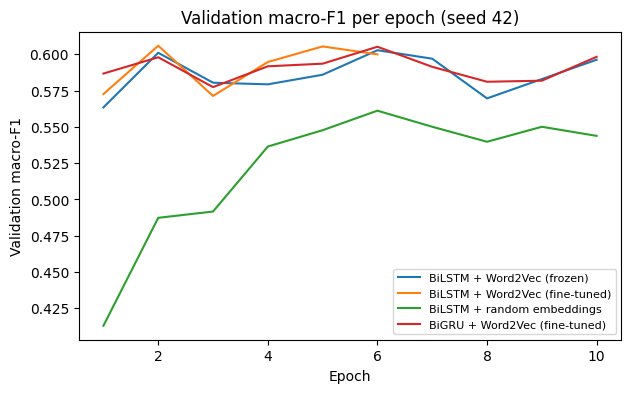

In [13]:
plt.figure(figsize=(7, 4))
for name, r in runs.items():
    plt.plot(range(1, len(r[0]["history"]) + 1), r[0]["history"], label=name)
plt.xlabel("Epoch"); plt.ylabel("Validation macro-F1")
plt.title("Validation macro-F1 per epoch (seed 42)")
plt.legend(fontsize=8); plt.show()

### Observations
- The three Word2Vec models reach 0.572-0.580 test macro-F1, against 0.540 for random embeddings. The gap of 0.03-0.04 is several times the seed-to-seed spread (std 0.01 or less), so embeddings trained on the tweets help even with this little text.
- Fine-tuning versus freezing the embeddings (0.580 vs 0.572) and BiLSTM versus BiGRU (0.580 vs 0.575) differ by 0.005-0.008, which is within seed noise. Neither comparison is conclusive.
- No sequence model beats the character-level TF-IDF baseline (0.597 test, 0.642 validation). The best one, the fine-tuned BiLSTM, is only slightly above the word-level baseline (0.567, a single run).
- Best epochs come early: 2-6 for the Word2Vec models and 5-10 with random embeddings. Validation scores stop improving after a few epochs, consistent with fast overfitting on a small training set.
- Validation scores sit 0.03-0.04 above test for the Word2Vec models (0.009 for random embeddings), partly because the best epoch is chosen on validation.
- The character baseline probably stays ahead because of the 28% `<unk>` rate noted above: it works on subword pieces, so inflected and misspelled words still contribute features.